In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_csv("/content/synthetic_fooddelivery_dataset.csv")
print("Shape:", df.shape)

Shape: (8500, 11)


In [14]:
df.head()

,ID_Pesanan,Waktu_Transaksi,Kategori_Menu,Harga_Pesanan,Jarak_Kirim_KM,Waktu_Tunggu_Menit,Rating_Pelanggan,Ulasan_Teks,Status_Promo,Tingkat_Keluhan,Status_Pesanan
0,ORD-2024-000001,2024-03-22 13:15:14,Kopi,9000,NaN,27,4.0,Sesuai pesanan,False,Tidak Ada,Selesai
1,ORD-2024-000002,2024-01-14 17:05:37,Mie,21000,3.742238,37,NaN,NaN,False,Tidak Ada,Selesai
2,ORD-2024-000003,2024-01-04 12:32:38,Martabak,33500,12.677149,49,NaN,NaN,True,Rendah,Selesai
3,ORD-2024-000004,2024-01-26 22:34:26,Kopi,13500,2.338085,20,5.0,Mantap gan!,False,Tidak Ada,Selesai
4,ORD-2024-000005,2024-03-16 11:48:51,Ayam,47500,0.949764,27,4.0,Top bgt kualitasnya,True,Rendah,Selesai


In [15]:
print(df.isnull().sum())

ID_Pesanan               0
Waktu_Transaksi          0
Kategori_Menu            0
Harga_Pesanan            0
Jarak_Kirim_KM         595
Waktu_Tunggu_Menit       0
Rating_Pelanggan      1700
Ulasan_Teks           1700
Status_Promo             0
Tingkat_Keluhan          0
Status_Pesanan           0
dtype: int64


In [16]:
df = df.dropna()
print("After cleaning:", df.shape)

After cleaning: (6323, 11)


In [30]:
avg_time=df['Waktu_Tunggu_Menit'].mean()
print("Average Delivery Time:", avg_time)
max_time= df['Waktu_Tunggu_Menit'].max()
print("Maximum Delivery Time:", max_time)

Average Delivery Time: 22.730349517634036
Maximum Delivery Time: 112


In [31]:
slowest_menu=df.groupby('Kategori_Menu')['Waktu_Tunggu_Menit'].mean().idxmax()
slowest_menu_time=df.groupby('Kategori_Menu')['Waktu_Tunggu_Menit'].mean().max()
print("Slowest Menu Category:", slowest_menu)

Slowest Menu Category: Mie


In [18]:
df['Jarak_Kirim_KM'].describe()

,Jarak_Kirim_KM
count,6323.000000
mean,3.118291
std,3.027347
min,0.500000
25%,0.900790
50%,2.160250
75%,4.213734
max,25.000000


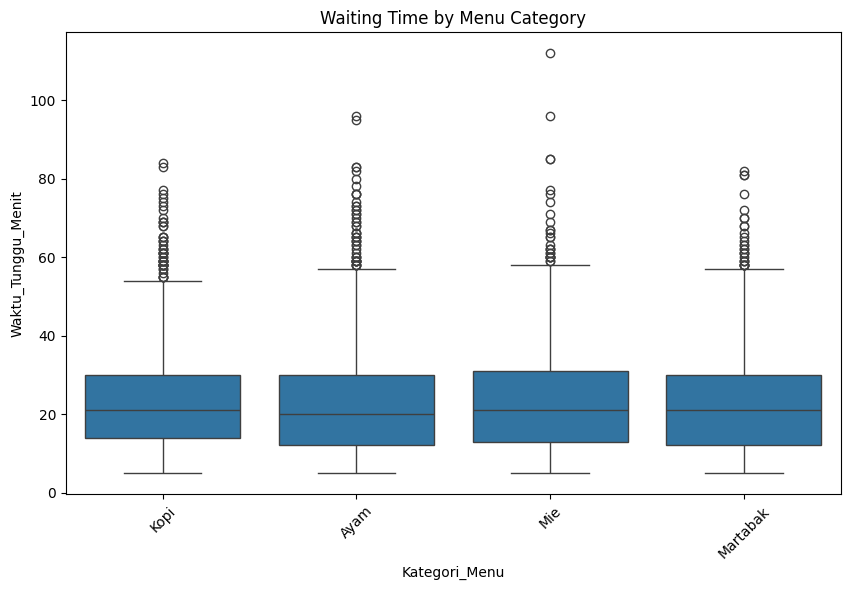

In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Kategori_Menu', y='Waktu_Tunggu_Menit', data=df)
plt.title('Waiting Time by Menu Category')
plt.xticks(rotation=45)
plt.show()

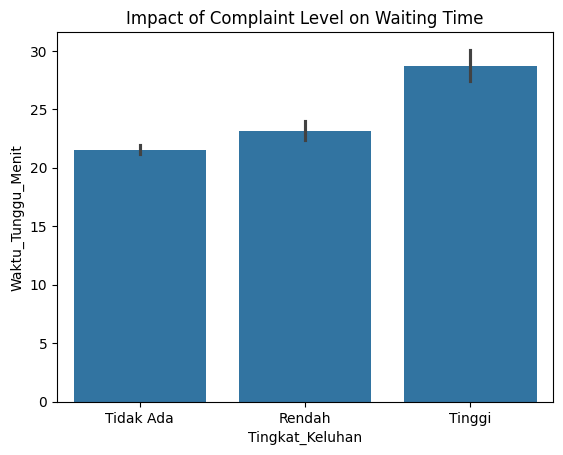

In [22]:
sns.barplot(x='Tingkat_Keluhan', y='Waktu_Tunggu_Menit', data=df)
plt.title('Impact of Complaint Level on Waiting Time')
plt.show()

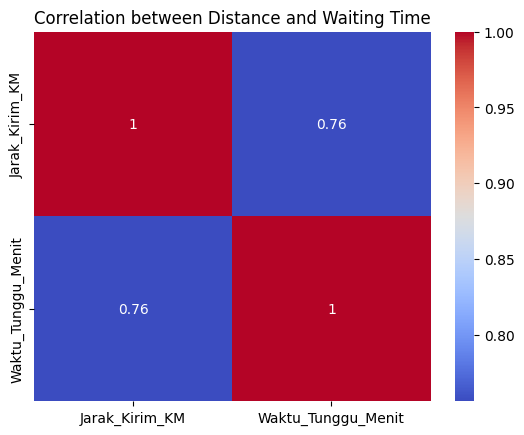

In [24]:
sns.heatmap(df[['Jarak_Kirim_KM', 'Waktu_Tunggu_Menit']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation between Distance and Waiting Time')
plt.show()

In [26]:
print("Average Delivery Time:", df['Waktu_Tunggu_Menit'].mean())

Average Delivery Time: 22.730349517634036


In [28]:
print("Slowest Menu Category:", df.groupby('Kategori_Menu')['Waktu_Tunggu_Menit'].mean().idxmax())

Slowest Menu Category: Mie


In [29]:
print("Slowest Complaint Level:", df.groupby('Tingkat_Keluhan')['Waktu_Tunggu_Menit'].mean().idxmax())

Slowest Complaint Level: Tinggi


In [32]:
Correlation =df[['Jarak_Kirim_KM', 'Waktu_Tunggu_Menit']].corr().iloc[0,1]
print(Correlation)

0.7561028886647554
